<a href="https://colab.research.google.com/github/themdanas/Deep_Generative_Models/blob/main/DDPM_Forward_Diffusion_Process.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


In [ ]:
#image size
H,W = 64,64

#background = -1 (black), forground = +1 white
x0 = -np.ones((H,W), dtype=np.float32)

#draw a simple "T"
x0[10:54, 30:34] = 1.0 #vertical stroke
x0[10:14, 18:46] = 1.0 #top stroke


### Defining our defusion schedule (your beta, your alpha)

In [ ]:
T=100 # no of diffusion steps

#IMPORTANT: beta_i must be in (0,1)
beta = np.linspace(0.01,0.30,T).astype(np.float32)

#our defination
alpha = np.sqrt(1.0 - beta**2).astype(np.float32)

### forward diffusion process (markov process)

so here we are adding the mean with sd*random no.

so that's how the values of the pixel changes for every pixel


In [ ]:
xt = x0.copy()
snapshot = {0: xt.copy()}

keep_steps = [1,5,10,20,40,60,80,100]

for i in range(1, T+1):
  b= beta[i-1]
  a = alpha[i-1]

  z = np.random.randn(H,W).astype(np.float32) #z_i ~ N(0,I)
  xt = a * xt + b*z  # step formula

  if i in keep_steps:
    snapshot[i] = xt.copy()



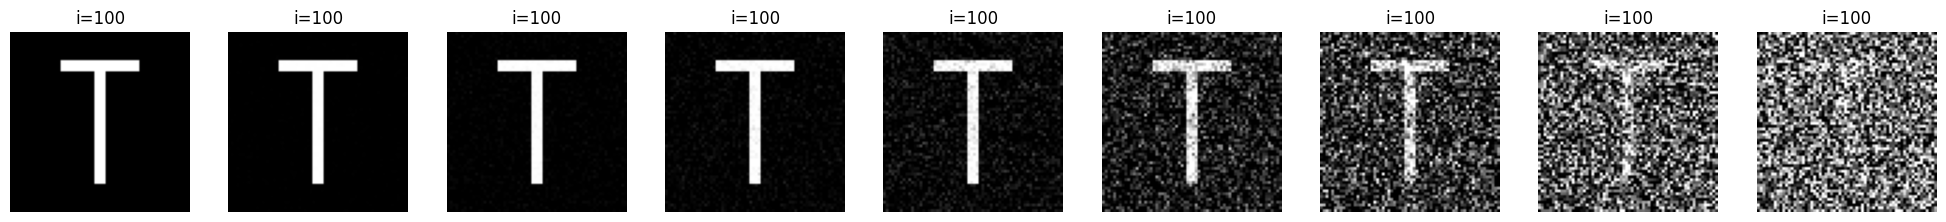

In [ ]:
steps = sorted(snapshot.keys())

plt.figure(figsize=(2.2 * len(steps), 2.2))
for k,t in enumerate(steps):
  ax = plt.subplot(1, len(steps), k+1)
  ax.imshow(np.clip(snapshot[t],-1,1),cmap="gray", vmin=-1, vmax=1)
  ax.set_title(f"i={i}")
  ax.axis("off")


plt.tight_layout()
plt.show()